# Hair sticker merge — v2, auto-fitting placement

**What was wrong.** The old `overlay_sticker()` scaled the sticker's *bounding box* to
the head width and dropped it at `top_frac=0.36` of its own height. A wig's bounding box
contains pigtails, a topknot and whatever padding the artist left, so "36% down the PNG"
lands somewhere different on every sticker. That is why the wig floated instead of sitting
on the head.

**What v2 does instead.** It finds the **face opening** inside the clipart — the enclosed
transparent region the face is drawn to show through — and measures three things from it:

| measured in the sticker | matched to, on the user | decides |
|---|---|---|
| width of the face opening | face width (landmarks 234 ↔ 454) | **scale** |
| horizontal centre of the opening | face midline | **x** |
| crown — first row reaching most of the skull-level width | top of the skull | **y** |

Scale comes from the opening because the face has to fit through it. Position comes from the
crown because that is where hair physically rests. Neither needs to know what *kind* of style
it is: a deep fringe has its opening far below its crown, so it lands low on the forehead; an
open forehead has it close to the crown, so it stops at the hairline. The art's own geometry
carries that information. `scale` and `y_off` no longer need tuning per PNG.

One guard rail: the top of the opening is never allowed above the user's own hairline, or
their scalp shows through — and once their hair has been inpainted away, that gap is a bald
dome. Tested across a cartoon wig, a photographic quiff, a silhouette, long waves, long
straight hair and an afro, with no per-sticker settings.

**Also fixed**
- `keep_main_object` throws away everything that is not the hair: watermarks, caption
  strips, "Visit" buttons, site icons, and the second and third wig in a multi-wig file
- one affine warp does scale + roll + placement, so nothing clips at the corners
- the face from just above the eyes down is composited back **on top**, so bangs own
  the forehead but can never cover the eyes
- head roll is followed; head yaw past ~35° is flagged, because a flat sticker cannot turn
- inpainting of the user's own hair is limited to the head box and skipped where the
  sticker already covers, so TELEA stops smearing the background
- a *screenshot* of a transparent PNG — where the grey checkerboard is painted into the
  pixels and alpha is a useless 255 — is cut out by colour instead of by flood fill
- `tone=` matches a photographic cut-out's brightness to the photo's lighting


## 1 · Install + models

In [1]:
!pip install -q mediapipe opencv-python-headless

import os, urllib.request
os.makedirs("/content/models", exist_ok=True)
for p, u in {
    "/content/models/selfie_multiclass_256x256.tflite":
        "https://storage.googleapis.com/mediapipe-models/image_segmenter/selfie_multiclass_256x256/float32/latest/selfie_multiclass_256x256.tflite",
    "/content/models/face_landmarker.task":
        "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/latest/face_landmarker.task",
}.items():
    if not os.path.exists(p):
        print("downloading", os.path.basename(p))
        urllib.request.urlretrieve(u, p)
print("models ready")

downloading selfie_multiclass_256x256.tflite
downloading face_landmarker.task
models ready


## 2 · Robust loading + face detection
Unchanged from your notebook: EXIF, downscale, and four detection passes.

In [2]:
import cv2
import numpy as np
import mediapipe as mp
from PIL import Image, ImageOps
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

SEG = vision.ImageSegmenter.create_from_options(vision.ImageSegmenterOptions(
    base_options=mp_python.BaseOptions(model_asset_path="/content/models/selfie_multiclass_256x256.tflite"),
    running_mode=vision.RunningMode.IMAGE, output_confidence_masks=True, output_category_mask=True))

def _mk_face(conf):
    return vision.FaceLandmarker.create_from_options(vision.FaceLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path="/content/models/face_landmarker.task"),
        running_mode=vision.RunningMode.IMAGE, num_faces=1,
        min_face_detection_confidence=conf, min_face_presence_confidence=conf))

FACE_HI, FACE_LO = _mk_face(0.5), _mk_face(0.2)

def load_image(path_or_bytes, max_side=1280):
    """EXIF-correct, RGB, downscaled. cv2.imread alone is what broke the earlier run."""
    import io
    src = io.BytesIO(path_or_bytes) if isinstance(path_or_bytes, (bytes, bytearray)) else path_or_bytes
    pil = ImageOps.exif_transpose(Image.open(src)).convert("RGB")
    if max_side:
        pil.thumbnail((max_side, max_side), Image.LANCZOS)
    return cv2.cvtColor(np.array(pil), cv2.COLOR_RGB2BGR)

def _detect(bgr, det):
    r = det.detect(mp.Image(image_format=mp.ImageFormat.SRGB,
                            data=cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)))
    if not r.face_landmarks:
        return None
    h, w = bgr.shape[:2]
    return np.array([[p.x * w, p.y * h] for p in r.face_landmarks[0]], np.float32)

def person_mask(bgr):
    r = SEG.segment(mp.Image(image_format=mp.ImageFormat.SRGB,
                             data=cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)))
    h, w = bgr.shape[:2]
    m = r.confidence_masks[0].numpy_view().astype(np.float32)      # background
    if m.shape != (h, w):
        m = cv2.resize(m, (w, h))
    return 1.0 - m

def hair_mask(bgr, box=None, crop_size=512):
    """Hair confidence mask. With a box, the crop is segmented for far more detail."""
    r = SEG.segment(mp.Image(image_format=mp.ImageFormat.SRGB,
                             data=cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)))
    h, w = bgr.shape[:2]
    full = r.confidence_masks[1].numpy_view().astype(np.float32)
    if full.shape != (h, w):
        full = cv2.resize(full, (w, h))
    if box is None:
        return full
    X0, Y0, X1, Y1 = box
    if X1 - X0 < 16 or Y1 - Y0 < 16:
        return full
    crop = cv2.resize(bgr[Y0:Y1, X0:X1], (crop_size, crop_size), interpolation=cv2.INTER_CUBIC)
    rc = SEG.segment(mp.Image(image_format=mp.ImageFormat.SRGB,
                              data=cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)))
    hm = rc.confidence_masks[1].numpy_view().astype(np.float32)
    back = np.zeros((h, w), np.float32)
    back[Y0:Y1, X0:X1] = cv2.resize(hm, (X1 - X0, Y1 - Y0), interpolation=cv2.INTER_LINEAR)
    return np.maximum(full, back)

def detect_face(bgr, verbose=True):
    """Four attempts before failing."""
    lm = _detect(bgr, FACE_HI)
    if lm is not None:
        if verbose: print("  face found (pass 1)")
        return lm
    lm = _detect(bgr, FACE_LO)
    if lm is not None:
        if verbose: print("  face found (pass 2: low confidence)")
        return lm
    pm = person_mask(bgr)                       # pass 3/4: zoom the head, map back
    ys, xs = np.where(pm > 0.5)
    if len(ys):
        h, w = bgr.shape[:2]
        top = ys.min(); band = ys <= top + (ys.max() - top) * 0.45
        cx = int(xs[band].mean()); cy = int(top + (ys.max() - top) * 0.16)
        side = int(max(80, (xs[band].max() - xs[band].min()) * 1.4))
        X0, Y0 = max(0, cx - side // 2), max(0, cy - side // 2)
        X1, Y1 = min(w, cx + side // 2), min(h, cy + side // 2)
        if X1 - X0 > 32 and Y1 - Y0 > 32:
            crop = bgr[Y0:Y1, X0:X1]
            s = 640 / max(crop.shape[:2])
            big = cv2.resize(crop, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC)
            for det, label in ((FACE_HI, "3"), (FACE_LO, "4")):
                lm = _detect(big, det)
                if lm is not None:
                    if verbose: print(f"  face found (pass {label}: head zoom)")
                    return lm / s + np.array([X0, Y0], np.float32)
    if verbose: print("  NO FACE FOUND after 4 attempts")
    return None

print("detection ready")

detection ready


## 3 · Sticker alpha
Clean cut-out, plus `drop_specks` so a watermark in the corner can no longer stretch the bounding box.

In [3]:
def _despill(rgba):
    """Pull white fringing out of semi-transparent edge pixels."""
    out = rgba.copy()
    a = out[:, :, 3:4].astype(np.float32) / 255.0
    edge = ((a > 0.05) & (a < 0.95)).squeeze()
    if edge.any():
        bgr = out[:, :, :3].astype(np.float32)
        core = (a.squeeze() >= 0.95)
        if core.sum() > 20:
            mean_core = bgr[core].mean(0)
            bgr[edge] = bgr[edge] * 0.45 + mean_core * 0.55
            out[:, :, :3] = np.clip(bgr, 0, 255).astype(np.uint8)
    return out

def prepare_hair_rgba(style_raw, white_thresh=238, soft=True, tol=None):
    """Clipart or a cut-out photo -> BGRA with clean alpha.

    Handles three kinds of input:
      * a real transparent PNG                      -> used as is
      * art on a flat white background              -> soft, anti-aliased alpha
      * a SCREENSHOT of a transparent PNG, where the
        grey/white checkerboard is painted into the
        pixels and alpha is a useless 255 everywhere -> hard alpha, no halo
    Returns None if there is no light background at all (i.e. a photo).
    """
    if style_raw is None:
        return None
    if style_raw.ndim == 2:
        style_raw = cv2.cvtColor(style_raw, cv2.COLOR_GRAY2BGR)
    if style_raw.shape[2] == 4 and style_raw[:, :, 3].min() < 240:
        return _despill(style_raw)                      # already transparent
    bgr = style_raw[:, :, :3]
    h, w = bgr.shape[:2]

    # Judge the rim by how MUCH of it is light, not by its average: a caption
    # strip or a "Visit" button along one edge drags the mean below any
    # threshold and gets a perfectly good cut-out rejected.
    rim = np.concatenate([bgr[0], bgr[-1], bgr[:, 0], bgr[:, -1]], 0)
    rim_hsv = cv2.cvtColor(rim.reshape(-1, 1, 3), cv2.COLOR_BGR2HSV).reshape(-1, 3)
    light = (rim_hsv[:, 1] < 40) & (rim_hsv[:, 2] > 215)
    if light.mean() < 0.55:
        return None                                     # a portrait photo, not a cut-out
    rim_v = rim_hsv[light, 2].astype(np.float32)
    spread = float(rim_v.max() - rim_v.min())           # 0 on white, ~21 on a checkerboard

    if soft and spread <= 10:
        # Flat white background. Flood from the corners, then grade the edge by
        # how white each pixel is, which keeps anti-aliased clipart outlines soft.
        ffmask = np.zeros((h + 2, w + 2), np.uint8)
        tmp = bgr.copy()
        for seed in [(0, 0), (w - 1, 0), (0, h - 1), (w - 1, h - 1)]:
            cv2.floodFill(tmp, ffmask, seed, (0, 0, 0), (tol or 18,) * 3, (tol or 18,) * 3,
                          flags=4 | (255 << 8))
        outside = ffmask[1:-1, 1:-1].astype(bool)
        mx = bgr.max(axis=2).astype(np.float32)
        mn = bgr.min(axis=2).astype(np.float32)
        whiteness = np.clip((mx - 200) / max(1.0, (white_thresh - 200)), 0, 1)
        whiteness *= np.clip(1.0 - (mx - mn) / 40.0, 0, 1)       # grey/white only
        alpha = np.where(outside, (1.0 - whiteness), 1.0)
        alpha = np.where(outside & (whiteness >= 1.0), 0.0, alpha)
        alpha = cv2.GaussianBlur((alpha * 255).astype(np.uint8), (3, 3), 0)
    else:
        # Patterned background — a screenshot of a transparent PNG. Flood fill is
        # the wrong tool here: without FLOODFILL_FIXED_RANGE it compares each
        # pixel to its NEIGHBOUR, so on a photographic cut-out it walks down the
        # soft edge gradient and eats the whole hair. Select by colour instead.
        # The checkerboard is grey (no saturation) and bright; hair is neither.
        hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
        v_lo = float(np.percentile(rim_v, 5)) - 14
        cand = ((hsv[:, :, 1] < 40) & (hsv[:, :, 2] > v_lo)).astype(np.uint8)
        n, lab, cstats, _ = cv2.connectedComponentsWithStats(cand, 4)
        edge = np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))
        outside = np.isin(lab, edge[edge != 0])

        # The face opening is background too, but it is enclosed by hair so it
        # never touches the rim. Recover it by matching the checkerboard: same
        # mean brightness AND same local contrast as the rim. A real highlight
        # inside the hair is smooth, so its contrast is far lower.
        V = hsv[:, :, 2].astype(np.float32)
        texture = np.abs(V - cv2.medianBlur(hsv[:, :, 2], 5).astype(np.float32))
        if outside.any():
            ref_v, ref_t = float(V[outside].mean()), float(texture[outside].mean())
            for i in range(1, n):
                if cstats[i, cv2.CC_STAT_AREA] < 0.003 * h * w or np.isin(i, edge):
                    continue
                m = lab == i
                if abs(float(V[m].mean()) - ref_v) < 12 and abs(float(texture[m].mean()) - ref_t) < 6:
                    outside |= m
        # Close pinholes: single bright pixels inside the hair are highlights.
        outside = cv2.morphologyEx(outside.astype(np.uint8), cv2.MORPH_OPEN,
                                   np.ones((2, 2), np.uint8)).astype(bool)
        # Shave one pixel off: the boundary ring is hair blended with white
        # background, and keeping it reads as a pale halo once composited.
        keep = cv2.erode((~outside).astype(np.uint8), np.ones((3, 3), np.uint8), iterations=1)
        alpha = cv2.GaussianBlur(keep * 255, (0, 0), 0.8)

    return _despill(np.dstack([bgr, alpha]))


def load_sticker(path_or_bytes):
    """Read a hair PNG from a path or raw bytes and return clean BGRA."""
    if isinstance(path_or_bytes, (bytes, bytearray)):
        raw = cv2.imdecode(np.frombuffer(path_or_bytes, np.uint8), cv2.IMREAD_UNCHANGED)
    else:
        raw = cv2.imread(path_or_bytes, cv2.IMREAD_UNCHANGED)
    if raw is None:
        raise FileNotFoundError(path_or_bytes)
    st = prepare_hair_rgba(raw)
    if st is None:
        raise ValueError("No light background and no alpha — this looks like an uncut "
                         "photo. Cut it out first, or use art on white/checkerboard.")
    return tight_crop(keep_main_object(st))

print("alpha prep ready")

alpha prep ready


## 4 · Fitting geometry — the part that changed
Finds the face opening in the clipart and matches it to the head.

In [4]:
# ============================================================================
#  Sticker anatomy + placement maths.  Pure numpy/OpenCV, no MediaPipe.
#  This is the part that decides WHERE the wig goes, and it is what was wrong
#  before: the old code scaled the sticker's whole bounding box to the head
#  width and dropped it at a fixed fraction of its height.  A wig's bounding
#  box includes pigtails and empty padding, so that fraction is a different
#  place on every piece of art.
#
#  The fix: find the FACE OPENING inside the clipart.  Its top edge is the
#  hairline and its centre is the midline.  Those two features exist in every
#  wig drawing, so the same numbers fit every sticker.
# ============================================================================
import cv2
import numpy as np

FACE_OVAL = [10, 338, 297, 332, 284, 251, 389, 356, 454, 323, 361, 288, 397,
             365, 379, 378, 400, 377, 152, 148, 176, 149, 150, 136, 172, 58,
             132, 93, 234, 127, 162, 21, 54, 103, 67, 109]


# ------------------------------------------------------------------ cleaning
def keep_main_object(rgba, min_frac=0.004, pad_frac=0.02):
    """Keep the hair and throw away everything else in the file.

    Stock hair PNGs arrive with company: watermarks, caption strips, "Visit"
    buttons, site icons — and sometimes two or three wigs in one image. Keeping
    every component above a size threshold merges them all into one bounding
    box, which wrecks every measurement downstream.

    Rule: keep the largest component, plus any component that overlaps its
    (slightly padded) box — those are detached strands, braid tips, flyaways.
    A second wig sitting beside the first does not overlap, so it is dropped.
    """
    a = (rgba[:, :, 3] > 100).astype(np.uint8)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(a, 8)
    if n <= 2:
        return rgba
    areas = stats[1:, cv2.CC_STAT_AREA]
    main = 1 + int(np.argmax(areas))
    H, W = a.shape
    pad = int(max(H, W) * pad_frac)
    mx, my = stats[main, cv2.CC_STAT_LEFT] - pad, stats[main, cv2.CC_STAT_TOP] - pad
    mX = stats[main, cv2.CC_STAT_LEFT] + stats[main, cv2.CC_STAT_WIDTH] + pad
    mY = stats[main, cv2.CC_STAT_TOP] + stats[main, cv2.CC_STAT_HEIGHT] + pad

    keep = [main]
    for i in range(1, n):
        if i == main or stats[i, cv2.CC_STAT_AREA] < min_frac * areas.max():
            continue
        x, y = stats[i, cv2.CC_STAT_LEFT], stats[i, cv2.CC_STAT_TOP]
        X, Y = x + stats[i, cv2.CC_STAT_WIDTH], y + stats[i, cv2.CC_STAT_HEIGHT]
        if x < mX and X > mx and y < mY and Y > my:       # boxes intersect
            keep.append(i)
    out = rgba.copy()
    out[:, :, 3] = np.where(np.isin(lab, keep), out[:, :, 3], 0)
    return out


drop_specks = keep_main_object        # old name, same job


def tight_crop(rgba, thr=12):
    ys, xs = np.where(rgba[:, :, 3] > thr)
    if len(xs) == 0:
        return None
    return rgba[ys.min():ys.max() + 1, xs.min():xs.max() + 1]


# ------------------------------------------------------------ sticker anatomy
def analyze_sticker(rgba, alpha_thr=0.4):
    """Locate the face opening in a wig cut-out.

    Returns
      hairline_y : top edge of the opening -> sits on the user's hairline
      anchor_x   : horizontal centre of the opening -> sits on the face midline
      cap_width  : widest hair above the opening -> matches the skull width
      hole_width : widest part of the opening    -> matches the face width
      has_hole   : False for a solid silhouette, then proportions are assumed
    """
    a = rgba[:, :, 3] > int(alpha_thr * 255)
    h, w = a.shape
    left = np.full(h, -1, np.int32)
    right = np.full(h, -1, np.int32)
    gap = np.zeros(h, np.int32)
    gap_cx = np.zeros(h, np.float32)

    for y in range(h):
        xs = np.flatnonzero(a[y])
        if xs.size < 2:
            continue
        left[y], right[y] = xs[0], xs[-1]
        d = np.diff(xs)
        i = int(np.argmax(d))
        if d[i] > 1:                       # transparent run with hair on both sides
            gap[y] = int(d[i]) - 1
            gap_cx[y] = (xs[i] + xs[i + 1]) / 2.0

    width = np.where(left >= 0, right - left, 0)
    if width.max() <= 0:
        raise ValueError("sticker is empty")

    # Ignore gaps in the top 8%: a topknot or a parting can split the silhouette
    # there, and that is not the face.
    cand = np.flatnonzero((gap > 0.20 * w) & (np.arange(h) > 0.08 * h))
    has_hole = cand.size >= max(4, int(0.04 * h))

    if has_hole:
        hairline_y = int(cand[0])
        # Measure the opening over the band where cheeks would be. Scanning
        # further down reads the flare where long hair separates, which is not
        # the face and makes the opening look far wider than it is.
        cap0 = float(width[:max(1, hairline_y)].max()) if hairline_y > 2 else float(width.max())
        span = max(24.0, 0.75 * (cap0 if cap0 > 0 else w))
        near = cand[(cand >= hairline_y) & (cand <= hairline_y + span)]
        if near.size < 3:
            near = cand[cand <= hairline_y + 0.35 * h]
        # Take the WIDE end of that band, not the middle: art routinely drapes
        # hair over the cheeks, so the opening narrows as it goes down. Its
        # widest point, just under the fringe, is what the face has to fit.
        hole_width = float(np.percentile(gap[near], 85))
        anchor_x = float(np.median(gap_cx[near]))
    else:
        hairline_y = int(0.38 * h)
        hole_width = 0.0
        anchor_x = w / 2.0

    # The cap band is the hair above the opening. On a centre-parted wig the
    # opening starts near the very top and that band is almost empty, so widen
    # it — otherwise the skull width is read off a few pixels of parting.
    cap_end = hairline_y if (has_hole and hairline_y >= 0.18 * h) else int(0.50 * h)
    band = width[:max(1, cap_end)]
    cap_width = float(band.max()) if band.size and band.max() > 0 else float(width.max())
    if cap_width < hole_width:
        cap_width = float(width.max())

    # Vertical anchor: the row where the hair is widest *above* the opening.
    # On a head that row is the temple line, whatever the art does above it
    # (a bun, a topknot, volume) or below it (pigtails, long strands).
    rows = np.flatnonzero(band >= 0.97 * band.max()) if band.size and band.max() > 0 else np.array([0])
    cap_y = float(rows.mean())
    if not has_hole and left[int(cap_y)] >= 0:
        anchor_x = float((left[int(cap_y)] + right[int(cap_y)]) / 2.0)

    # Skull-level width: how wide the hair is at the row where the face starts.
    # This tracks the head. cap_width does not — on long hair its maximum is the
    # flare down by the shoulders, and on an afro it is the widest curl.
    skull_w = float(width[int(hairline_y)]) if has_hole and width[int(hairline_y)] > 0 else cap_width

    # The crown: scanning down from the top, the first row reaching most of the
    # skull-level width — searched only above the opening. Anchoring on the
    # art's top edge instead would hang the style off a bun or a topknot, which
    # sits above the head rather than on it.
    band_top = width[:max(1, int(hairline_y))]
    rows_wide = np.flatnonzero(band_top >= 0.62 * skull_w)
    crown_y = float(rows_wide[0]) if rows_wide.size else 0.0

    return {"hairline_y": float(hairline_y), "cap_y": cap_y, "crown_y": crown_y,
            "skull_w": skull_w, "anchor_x": anchor_x,
            "cap_width": cap_width, "hole_width": hole_width,
            "has_hole": bool(has_hole), "size": (w, h)}


# ----------------------------------------------------------------- head maths
def head_metrics(lm):
    """lm: (478,2) pixel landmarks from MediaPipe FaceLandmarker."""
    L, R = lm[234], lm[454]                 # temples, just in front of the ears
    TOP, CHIN, NOSE = lm[10], lm[152], lm[1]
    width = float(np.linalg.norm(R - L))
    height = float(np.linalg.norm(CHIN - TOP))
    cx = float((L[0] + R[0]) / 2.0)
    return {
        "width": width,                     # temple to temple = skull width
        "height": height,                   # hairline to chin
        "cx": cx,
        "hairline": (cx, float(TOP[1])),
        "temple": (cx, float((L[1] + R[1]) / 2.0)),   # the wig's widest row lands here
        "angle": float(-np.degrees(np.arctan2(R[1] - L[1], R[0] - L[0]))),
        "yaw": float((NOSE[0] - cx) / max(1.0, width / 2.0)),   # -1 .. 1
        "brow_y": float(min(lm[105][1], lm[334][1])),
        # Protection starts just above the EYES, not the brows: bangs are
        # supposed to cover the forehead, and cutting at the brow line leaves a
        # washed-out band where the feathered face mask blends into the hair.
        "eye_y": float(min(lm[159][1], lm[386][1])),
        "top": TOP, "chin": CHIN, "left": L, "right": R,
    }


def fit_params(hm, sa, face_fill=1.00, hair_thickness=1.20, scale_adjust=1.0,
               y_adjust=0.0, x_adjust=0.0, follow_yaw=True, crown_lift=0.25):
    """Return (scale, anchor_in_sticker, target_in_photo).

    Scale comes from the face opening (the face must fit it); position comes
    from the crown (hair rests on the skull).

    The earlier rules failed somewhere: widest-row -> temple line put cap-shaped
    cut-outs at the ears, and opening-top -> brow line needed a fringe detector
    that no measurement separated reliably.
    """
    w, h = sa["size"]
    if sa["has_hole"] and sa["hole_width"] > 0.25 * sa["cap_width"]:
        scale = (hm["width"] * face_fill) / max(1.0, sa["hole_width"])
        # Loose guard rails only. A voluminous style — an afro, big waves — is
        # legitimately several head-widths across, so clamping tightly here
        # shrinks it until it covers the face.
        lo = (hm["width"] * 1.05) / max(1.0, sa["skull_w"])
        hi = (hm["width"] * 2.40) / max(1.0, sa["skull_w"])
        scale = float(np.clip(scale, lo, hi))
    else:
        scale = (hm["width"] * hair_thickness) / max(1.0, sa["cap_width"])
    scale *= scale_adjust

    # Anchor the crown of the hair to the top of the skull. Where the fringe
    # ends then follows from the art's own geometry — a deep fringe has its
    # opening far below the crown and lands low on the forehead, an open
    # forehead has it close to the crown and stops at the hairline. No style
    # classification, no per-sticker numbers.
    anchor = (sa["anchor_x"], sa["crown_y"])
    ty = hm["hairline"][1] - crown_lift * hm["height"]

    # Guard rail: the top of the face opening must never land above the user's
    # own hairline, or their scalp shows through the gap — and if their hair was
    # inpainted away first, that gap is a bald dome.
    drop = (sa["hairline_y"] - sa["crown_y"]) * scale
    ty = max(ty, hm["hairline"][1] - drop)

    tx = hm["cx"] + hm["width"] * x_adjust
    if follow_yaw:
        tx += hm["yaw"] * hm["width"] * 0.12
    return float(scale), anchor, (float(tx), float(ty + hm["height"] * y_adjust))


def place_rgba(rgba, anchor, target, scale, angle_deg, out_hw):
    """One affine warp: anchor -> target, scaled and rotated about the anchor."""
    r = np.deg2rad(angle_deg)
    c, s = np.cos(r) * scale, np.sin(r) * scale
    ax, ay = anchor
    tx, ty = target
    M = np.float32([[c,  s,  tx - (c * ax + s * ay)],
                    [-s, c,  ty - (-s * ax + c * ay)]])
    return cv2.warpAffine(rgba, M, (out_hw[1], out_hw[0]),
                          flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT,
                          borderValue=(0, 0, 0, 0))


def alpha_over(base_bgr, warped_rgba):
    a = warped_rgba[:, :, 3:4].astype(np.float32) / 255.0
    out = base_bgr.astype(np.float32) * (1 - a) + warped_rgba[:, :, :3].astype(np.float32) * a
    return out.astype(np.uint8), a[:, :, 0]


# ------------------------------------------------------------ face protection
def face_front_mask(lm, shape, cut_y=None, shrink=0.97, feather=3):
    """The face, as a soft mask — pasted back on top so hair never covers eyes."""
    pts = lm[FACE_OVAL].astype(np.float32)
    c = pts.mean(0)
    pts = (c + (pts - c) * shrink).astype(np.int32)
    m = np.zeros(shape[:2], np.uint8)
    cv2.fillConvexPoly(m, cv2.convexHull(pts), 255)
    if cut_y is not None:
        m[:max(0, int(cut_y)), :] = 0       # above the brows the hair wins
    if feather > 0:
        m = cv2.GaussianBlur(m, (0, 0), feather)
    return m.astype(np.float32) / 255.0


def head_box(hm, shape, grow=1.9, up=0.9):
    h, w = shape[:2]
    cx, cy = hm["cx"], (hm["hairline"][1] + hm["chin"][1]) / 2.0
    half = hm["width"] * grow / 2.0
    return (int(max(0, cx - half)), int(max(0, cy - hm["height"] * up)),
            int(min(w, cx + half)), int(min(h, cy + hm["height"] * 1.1)))


def tint_sticker(rgba, hex_color, strength=0.9):
    hx = hex_color.lstrip("#")
    tgt = cv2.cvtColor(np.uint8([[[int(hx[4:6], 16), int(hx[2:4], 16), int(hx[0:2], 16)]]]),
                       cv2.COLOR_BGR2LAB).astype(np.float32)[0, 0]
    lab = cv2.cvtColor(rgba[:, :, :3], cv2.COLOR_BGR2LAB).astype(np.float32)
    w = (rgba[:, :, 3].astype(np.float32) / 255.0) * strength
    lab[..., 1] = lab[..., 1] * (1 - w) + tgt[1] * w
    lab[..., 2] = lab[..., 2] * (1 - w) + tgt[2] * w
    out = rgba.copy()
    out[:, :, :3] = cv2.cvtColor(lab.astype(np.uint8), cv2.COLOR_LAB2BGR)
    return out

## 5 · The merge

In [5]:
def remove_original_hair(bgr, hair01, keep01=None, box=None, grow=9, radius=6):
    """Inpaint the user's own hair, but only inside the head box and only where
    the sticker is not already covering it."""
    m = (hair01 > 0.45).astype(np.uint8)
    if keep01 is not None:
        m[keep01 > 0.35] = 0
    if box is not None:
        keep = np.zeros_like(m)
        keep[box[1]:box[3], box[0]:box[2]] = 1
        m *= keep
    if m.sum() == 0:
        return bgr
    k = np.ones((max(1, grow) | 1,) * 2, np.uint8)
    return cv2.inpaint(bgr, cv2.dilate(m, k, 1), radius, cv2.INPAINT_TELEA)


def match_lighting(rgba, photo_bgr, box, strength=0.5):
    """Nudge a photographic cut-out toward the photo's lighting.

    Luminance only. Chroma is left alone on purpose: pulling hair colour toward
    a reference patch that is mostly skin turns blond hair orange.
    """
    opaque = rgba[:, :, 3] > 200
    if opaque.sum() < 50 or strength <= 0:
        return rgba
    ref = photo_bgr[box[1]:box[3], box[0]:box[2]]
    if ref.size == 0:
        return rgba
    lab = cv2.cvtColor(rgba[:, :, :3], cv2.COLOR_BGR2LAB).astype(np.float32)
    ref_lab = cv2.cvtColor(ref, cv2.COLOR_BGR2LAB).astype(np.float32)
    s_hi = float(np.percentile(lab[:, :, 0][opaque], 85))
    r_hi = float(np.percentile(ref_lab[:, :, 0], 85))
    gain = 1.0 + strength * ((r_hi / max(1.0, s_hi)) - 1.0)
    lab[:, :, 0] = np.clip(lab[:, :, 0] * gain, 0, 255)
    out = rgba.copy()
    out[:, :, :3] = cv2.cvtColor(lab.astype(np.uint8), cv2.COLOR_LAB2BGR)
    return out


def debug_view(bgr, hm, box):
    d = bgr.copy()
    cv2.rectangle(d, box[:2], box[2:], (90, 90, 90), 1)
    cv2.line(d, tuple(np.int32(hm["left"])), tuple(np.int32(hm["right"])), (0, 200, 255), 2)
    cv2.circle(d, (int(hm["temple"][0]), int(hm["temple"][1])), 4, (0, 0, 255), -1)
    cv2.circle(d, (int(hm["hairline"][0]), int(hm["hairline"][1])), 4, (0, 255, 0), -1)
    return d


def smart_merge(user_bgr, style_rgba, *, remove_hair=True, protect_face=True,
                face_fill=1.00, scale_adjust=1.0, y_adjust=0.0, x_adjust=0.0,
                extra_rot=0.0, tint=None, follow_yaw=True, tone=0.0,
                inpaint_grow=9, inpaint_radius=6, debug=False, verbose=True):
    """user photo + clipart BGRA -> merged image, auto-fitted. Returns (result, info)."""
    info = {}
    lm = detect_face(user_bgr, verbose)
    if lm is None:
        return user_bgr, {"error": "no face detected"}

    hm = head_metrics(lm)
    st = tight_crop(keep_main_object(style_rgba))
    if st is None:
        return user_bgr, {"error": "sticker is empty"}
    if tint:
        st = tint_sticker(st, tint)

    box = head_box(hm, user_bgr.shape)
    if tone:
        st = match_lighting(st, user_bgr, box, strength=tone)

    sa = analyze_sticker(st)
    scale, anchor, target = fit_params(hm, sa, face_fill=face_fill, scale_adjust=scale_adjust,
                                       y_adjust=y_adjust, x_adjust=x_adjust, follow_yaw=follow_yaw)
    warped = place_rgba(st, anchor, target, scale,
                        hm["angle"] + extra_rot, user_bgr.shape[:2])
    cover = warped[:, :, 3].astype(np.float32) / 255.0

    base = user_bgr
    if remove_hair:
        hmask = hair_mask(user_bgr, box=box)
        base = remove_original_hair(user_bgr, hmask, keep01=cover, box=box,
                                    grow=inpaint_grow, radius=inpaint_radius)
        info["own_hair_px"] = int((hmask > 0.45).sum())

    out, _ = alpha_over(base, warped)

    if protect_face:            # eyes, nose and mouth always win over the hair
        fm = face_front_mask(lm, out.shape, cut_y=hm["eye_y"] - 0.03 * hm["height"])[:, :, None]
        out = (out.astype(np.float32) * (1 - fm) +
               user_bgr.astype(np.float32) * fm).astype(np.uint8)

    info.update(head_width=round(hm["width"]), roll=round(hm["angle"], 1),
                yaw=round(hm["yaw"], 2), scale=round(scale, 3),
                opening_px=round(sa["hole_width"] * scale),
                outer_px=round(sa["cap_width"] * scale),
                found_opening=sa["has_hole"], covered_px=int((cover > 0.5).sum()))
    if not sa["has_hole"]:
        info["warn"] = "no face opening found — fitted from proportions, check the result"
    if abs(hm["yaw"]) > 0.35:
        info["warn"] = "head turned too far for a flat sticker"
    if debug:
        info["debug"] = debug_view(user_bgr, hm, box)
    return out, info

print("smart_merge v2 ready")

smart_merge v2 ready


## 6 · Run it
Panel 3 shows the anchors: yellow = temple line the wig's widest row snaps to, red = target point, green = hairline.

Step 1: upload the USER photo


Saving man.png to man (3).png

Step 2: upload the HAIR png


Saving bule hair.png to bule hair (1).png
user 412x627 | sticker 352x466
sticker anatomy: {'hairline_y': 252.0, 'cap_y': 214.5, 'crown_y': 34.0, 'skull_w': 246.0, 'anchor_x': 146.0, 'cap_width': 252.0, 'hole_width': 179.0, 'has_hole': True, 'size': (352, 466)}
  face found (pass 1)
info: {'own_hair_px': 4375, 'head_width': 124, 'roll': 2.0, 'yaw': 0.12, 'scale': 0.691, 'opening_px': 124, 'outer_px': 174, 'found_opening': True, 'covered_px': 28964}


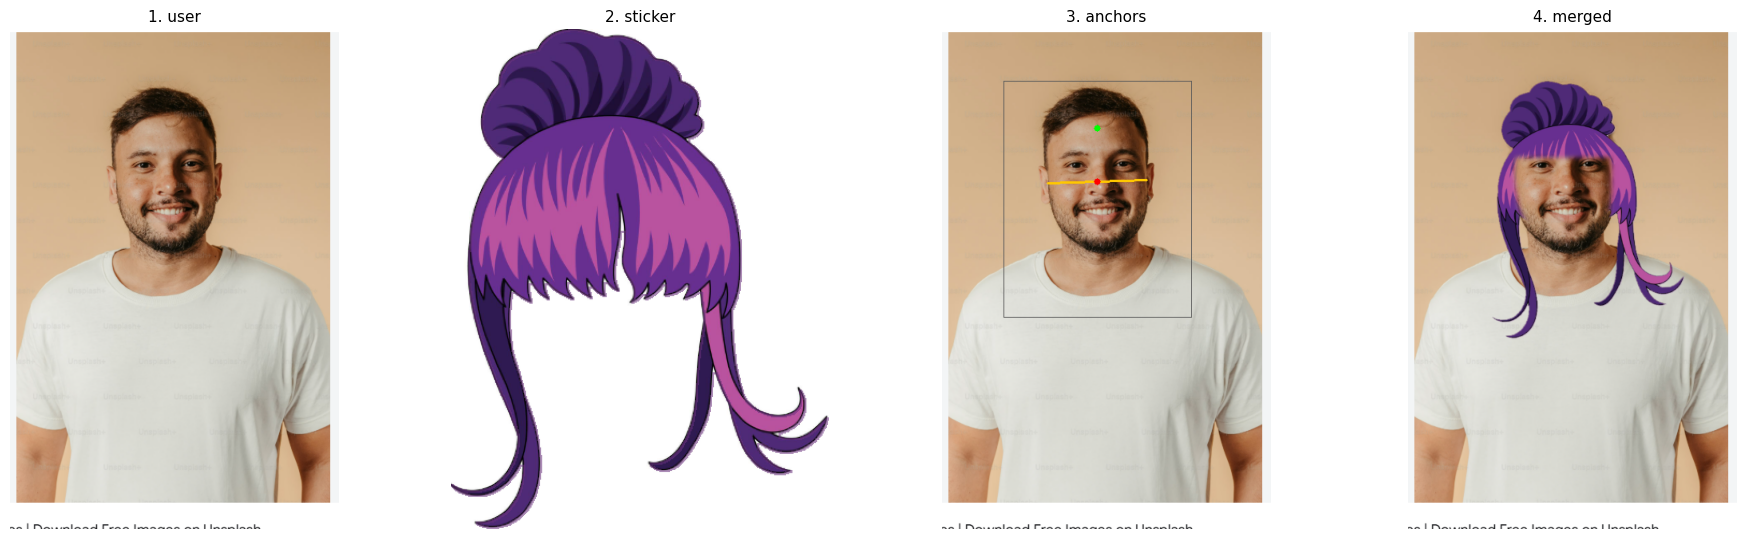

In [13]:
import matplotlib.pyplot as plt

USER_PATH  = "/content/man (1).png"      # <- your photo
HAIR_PATH  = "/content/bule hair (2).png" # <- the hair PNG

try:
    USER = load_image(USER_PATH)
    STYLE = load_sticker(HAIR_PATH)
except FileNotFoundError:
    from google.colab import files
    print("Step 1: upload the USER photo")
    USER = load_image(list(files.upload().values())[0])
    print("\nStep 2: upload the HAIR png")
    STYLE = load_sticker(list(files.upload().values())[0])

print(f"user {USER.shape[1]}x{USER.shape[0]} | sticker {STYLE.shape[1]}x{STYLE.shape[0]}")
print("sticker anatomy:", {k: (round(v, 1) if isinstance(v, float) else v)
                           for k, v in analyze_sticker(STYLE).items()})

RESULT, INFO = smart_merge(USER, STYLE, debug=True)
print("info:", {k: v for k, v in INFO.items() if k != "debug"})
cv2.imwrite("/content/merged.png", RESULT)

panels = [("1. user", USER), ("2. sticker", cv2.cvtColor(STYLE, cv2.COLOR_BGRA2BGR)),
          ("3. anchors", INFO.get("debug", USER)), ("4. merged", RESULT)]
fig, ax = plt.subplots(1, 4, figsize=(19, 5.5))
for a, (title, img) in zip(ax, panels):
    a.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    a.set_title(title, fontsize=11)
    a.axis("off")
plt.tight_layout(); plt.show()

## 7 · Fine adjustment (optional)

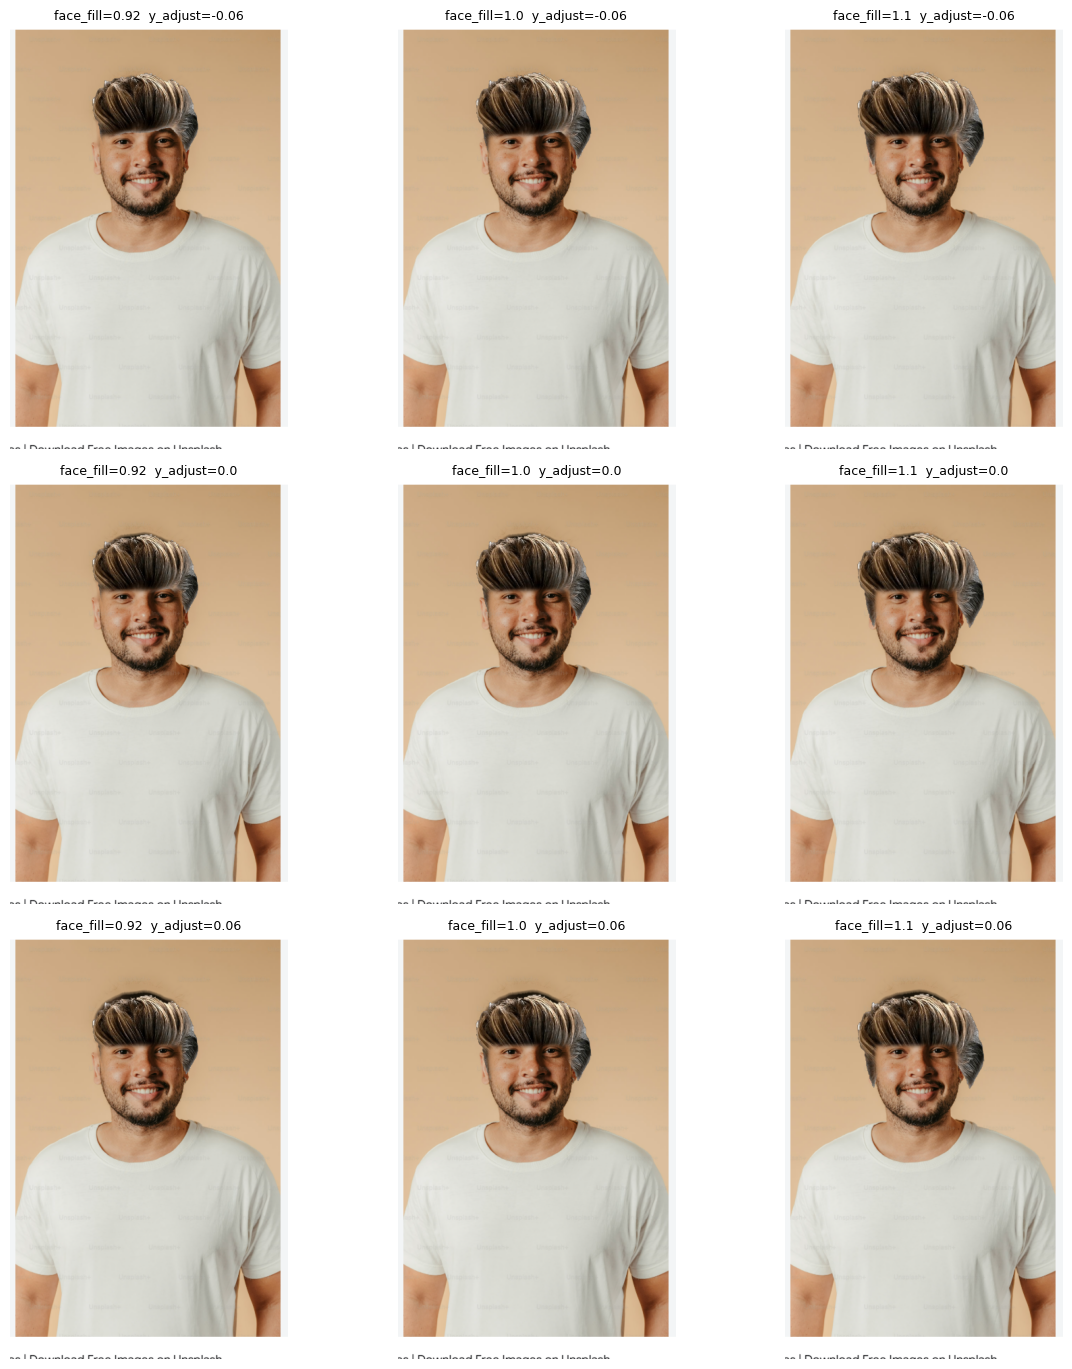

In [7]:
# Fine adjustment. The defaults should already be close; these are taste, not
# per-sticker calibration. face_fill < 1 = hair sits further onto the cheeks.
import matplotlib.pyplot as plt

fills = [0.92, 1.00, 1.10]
yoffs = [-0.06, 0.00, 0.06]

fig, ax = plt.subplots(len(yoffs), len(fills), figsize=(4.2 * len(fills), 4.6 * len(yoffs)))
for i, yo in enumerate(yoffs):
    for j, ff in enumerate(fills):
        img, _ = smart_merge(USER, STYLE, face_fill=ff, y_adjust=yo, verbose=False)
        a = ax[i][j]
        a.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        a.set_title(f"face_fill={ff}  y_adjust={yo}", fontsize=9)
        a.axis("off")
plt.tight_layout(); plt.show()

## 8 · Recolour the same sticker

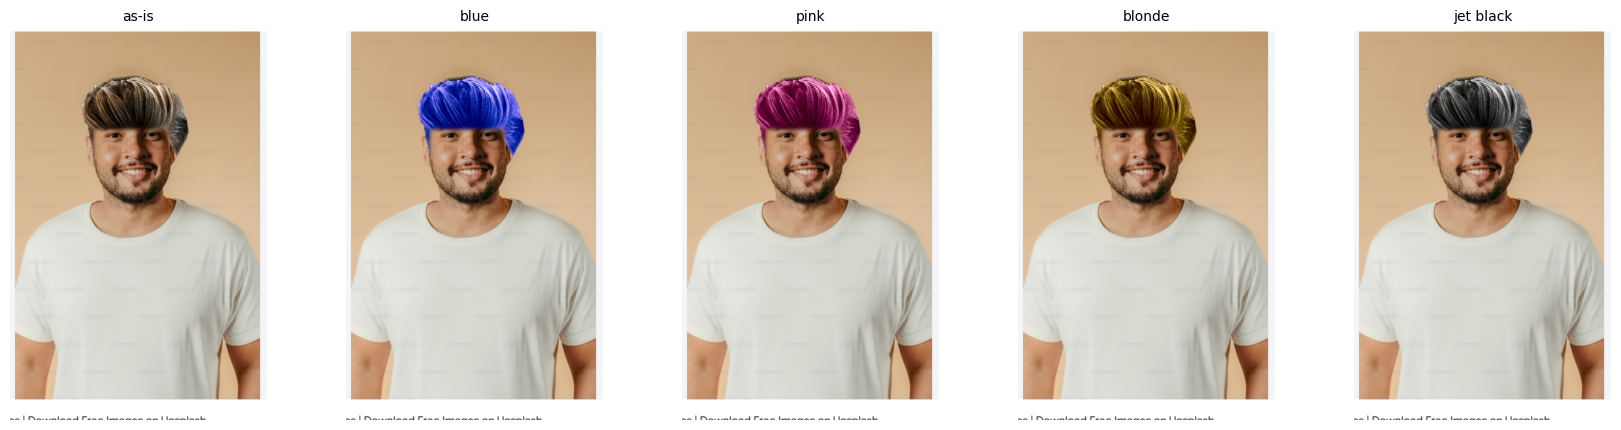

In [8]:
import matplotlib.pyplot as plt

TINTS = {"as-is": None, "blue": "#1E3FCF", "pink": "#E86AA6",
         "blonde": "#D4A94F", "jet black": "#141414"}

fig, ax = plt.subplots(1, len(TINTS), figsize=(3.4 * len(TINTS), 4.4))
for a, (name, hx) in zip(ax, TINTS.items()):
    img, _ = smart_merge(USER, STYLE, tint=hx, verbose=False)
    a.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    a.set_title(name, fontsize=10)
    a.axis("off")
plt.tight_layout(); plt.show()

## Notes for the app

**Nothing to store per sticker any more.** The old version needed a `scale` and `y_off`
saved next to every PNG. v2 reads those from the art itself, so a new wig can be dropped
into the catalogue with no calibration. Keep `face_fill` as one global taste setting.

**Cache per uploaded photo.** `detect_face` (~20 ms), the hair mask (~60 ms) and the
inpainted base (~80 ms) depend only on the photo. Cache all three and switching stickers
costs just `analyze_sticker` + one warp + the composite — about 15 ms, which is what makes
a gallery feel instant. `analyze_sticker` itself can be precomputed once per PNG at upload
time and stored as four numbers.

**One trade-off to know.** `protect_face=True` paints the face back on top from just above
the eyes down, which is what guarantees the hair never covers the eyes. If a sticker is *drawn* to
sweep across a cheek, that stroke gets clipped — pass `protect_face=False` for that one.

**Photographic cut-outs.** Real-hair PNGs work as well as clipart, with two extras. Pass
`tone=0.4`–`0.6` so the hair's brightness matches the photo's lighting; without it a studio
cut-out dropped into a warm snapshot reads as pasted. And grab the actual PNG rather than a
screenshot of one — the cut-out code copes with a painted-in checkerboard, but it has to
throw away a pixel of real hair at the edge to kill the halo.

**Sticker art rules.** A transparent PNG beats clipart on white, because the cut-out has to
guess. The art needs a visible gap where the face goes — that opening is what the scale is
measured from. Art with no opening at all still works, but falls back to proportions and
sets `found_opening: False`, so watch those.

**What the file may contain.** One hair object; if there are several, the largest wins and
the rest are dropped. Watermarks printed *over* the hair survive, because they are part of
the same connected blob — nothing can fix that but better source art.

**Where it still breaks.** Yaw. A flat 2D sticker can follow roll but not turn, so beyond
about 35° (flagged in `info["warn"]`) either skip the sticker or keep a three-quarter
variant of the art. Long hair over the shoulders is the other one: the inpaint only runs
inside the head box, so a user with long hair keeps some of it below the jaw.

**When to reach for a model instead.** This is the right tool for a Snapchat-style filter —
deterministic, instant, free, and the art is yours so results never surprise you. Use a
diffusion edit (Qwen-Image-2.1) or HairFastGAN only when the user wants their *real* hair
restyled photorealistically rather than a cartoon wig placed on top.
